<a href="https://colab.research.google.com/github/SitiMutmainah15/PEMBELAJARAN-MESIN_GENAP_2026/blob/main/JS08/Lab3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import HDBSCAN
from sklearn.datasets import make_blobs

# Dataset
centers = [[-0.85, -0.85], [-0.85, 0.85], [3, 3], [3, -3]]

X, labels_true = make_blobs(
    n_samples=750,
    centers=centers,
    cluster_std=[0.2, 0.35, 1.35, 1.35],
    random_state=0
)

print("Ukuran dataset:", X.shape)

Ukuran dataset: (750, 2)


In [14]:
def plot(X, labels, probabilities=None, parameters=None, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 4))

    if probabilities is None:
        probabilities = np.ones(len(labels))

    unique_labels = sorted(set(labels))
    colors = plt.cm.Spectral(np.linspace(0, 1, len(unique_labels)))

    for label, color in zip(unique_labels, colors):
        mask = labels == label

        if label == -1:
            ax.scatter(X[mask, 0], X[mask, 1],
                       c="black", marker="x", s=15)
        else:
            ax.scatter(X[mask, 0], X[mask, 1],
                       color=color, edgecolors="black",
                       linewidths=0.5,
                       s=5 + 25 * probabilities[mask])

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

    title = f"Estimated number of clusters: {n_clusters}"
    if parameters is not None:
        title += " | " + ", ".join(
            f"{k}={v}" for k, v in parameters.items()
        )

    ax.set_title(title)

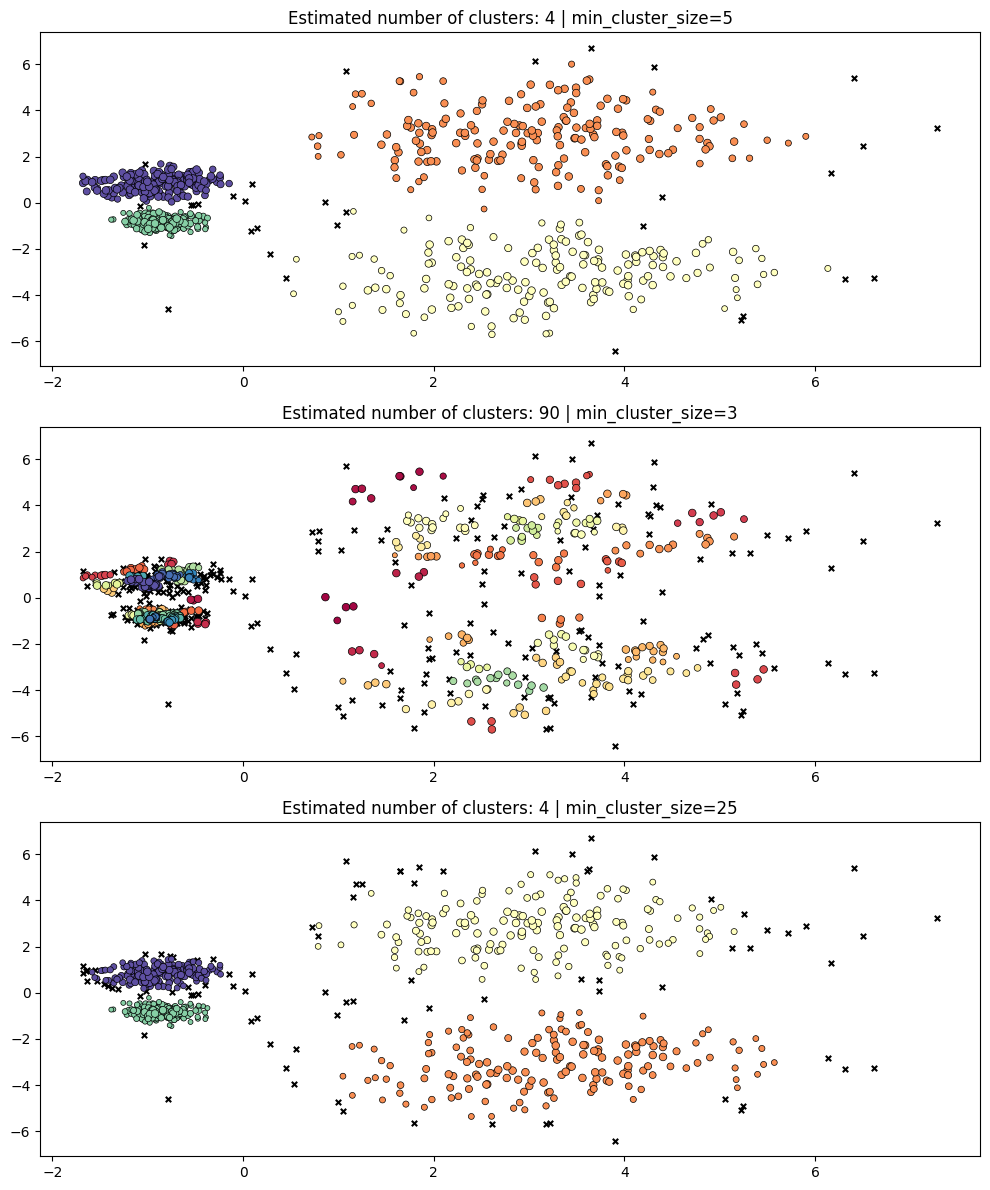

In [15]:
PARAM = (
    {"min_cluster_size": 5},
    {"min_cluster_size": 3},
    {"min_cluster_size": 25}
)

fig, axes = plt.subplots(3, 1, figsize=(10, 12))

for i, param in enumerate(PARAM):
    hdb = HDBSCAN(**param).fit(X)
    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])

plt.tight_layout()
plt.show()

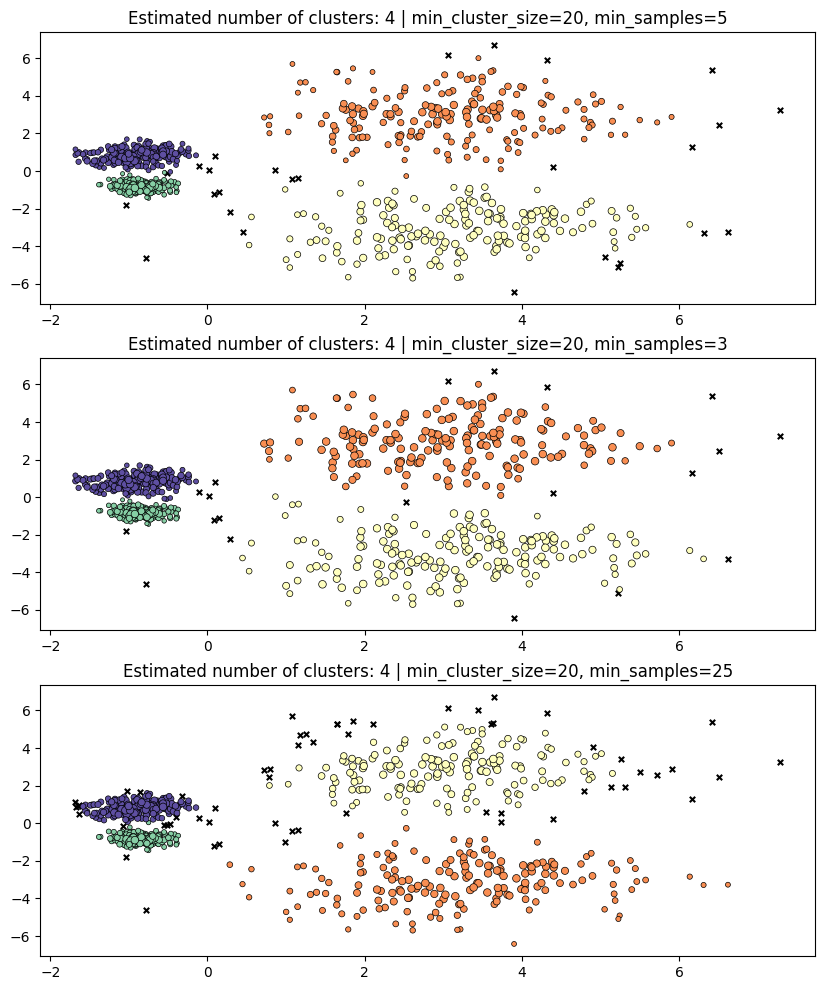

In [17]:
	PARAM = (
	    {"min_cluster_size": 20, "min_samples": 5},
	    {"min_cluster_size": 20, "min_samples": 3},
	    {"min_cluster_size": 20, "min_samples": 25},
	)
	fig, axes = plt.subplots(3, 1, figsize=(10, 12))
	for i, param in enumerate(PARAM):
	    hdb = hdbscan.HDBSCAN(**param).fit(X)
	    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])

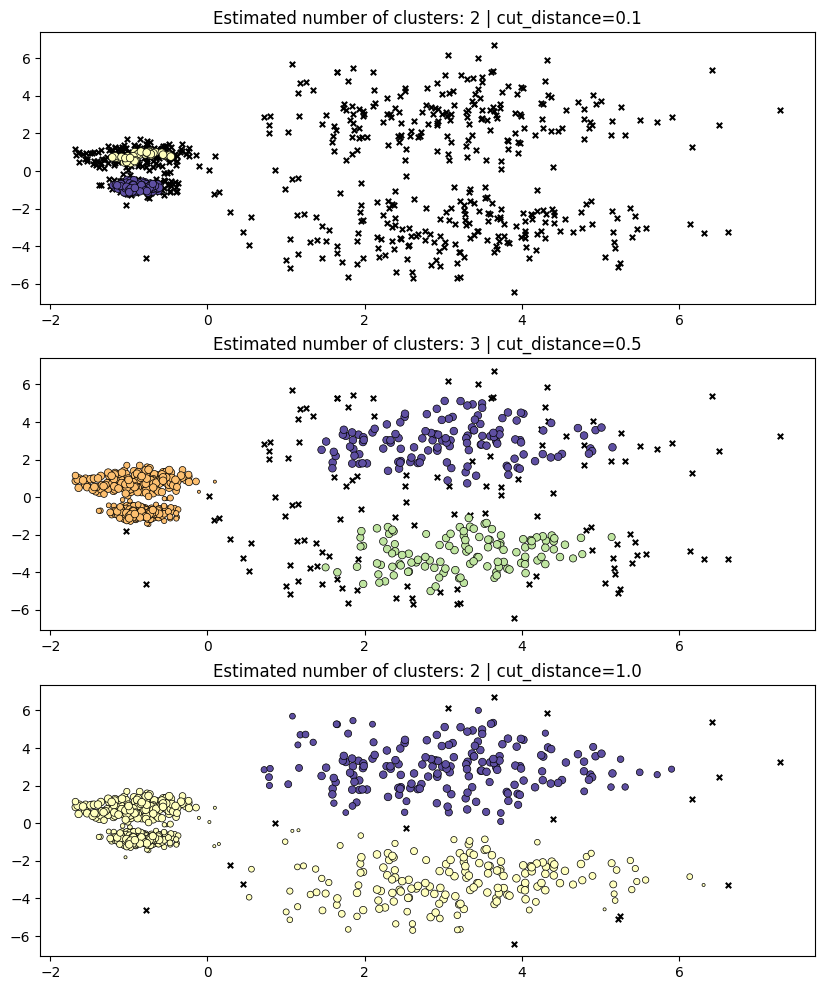

In [18]:
	PARAM = (
	    {"cut_distance": 0.1},
	    {"cut_distance": 0.5},
	    {"cut_distance": 1.0},
	)
	hdb = hdbscan.HDBSCAN().fit(X)
	fig, axes = plt.subplots(len(PARAM), 1, figsize=(10, 12))
	for i, param in enumerate(PARAM):
	    labels = hdb.dbscan_clustering(**param)
	    plot(X, labels, hdb.probabilities_, param, ax=axes[i])

In [19]:
	from sklearn.metrics import silhouette_score

	# Menghitung Silhouette Score untuk hasil clustering HDBSCAN
	sil_score = silhouette_score(X, hdb.labels_)
	print(f"Silhouette Score: {sil_score}")

Silhouette Score: 0.5743816709862986


In [20]:
	from sklearn.metrics import davies_bouldin_score

	# Menghitung Davies-Bouldin Index untuk hasil clustering HDBSCAN
	dbi_score = davies_bouldin_score(X, hdb.labels_)
	print(f"Davies-Bouldin Index: {dbi_score}")

Davies-Bouldin Index: 1.6436030674842066


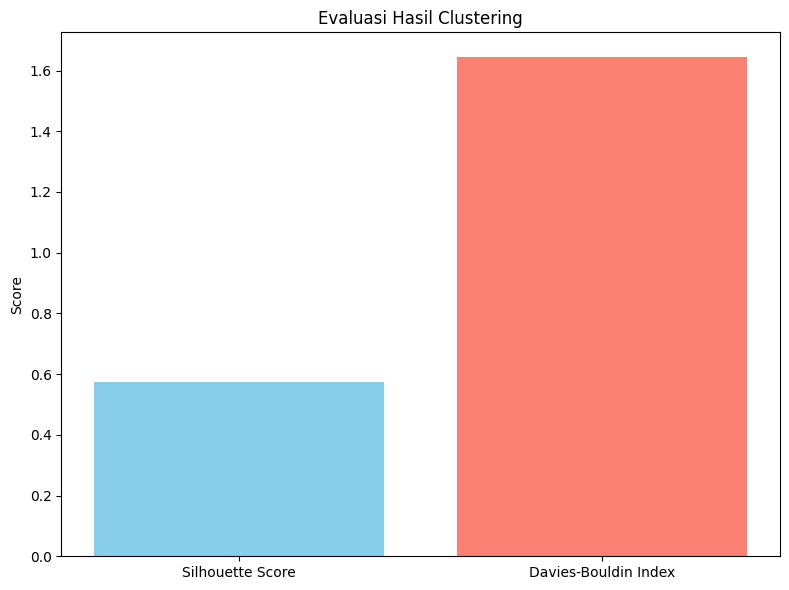

In [21]:
	# Kita ingin membandingkan DBI dan Silhouette Score untuk beberapa eksperimen
	scores = {
	    "Silhouette Score": sil_score,
	    "Davies-Bouldin Index": dbi_score
	}

	# Plot hasil evaluasi
	fig, ax = plt.subplots(figsize=(8, 6))
	ax.bar(scores.keys(), scores.values(), color=['skyblue', 'salmon'])
	ax.set_title("Evaluasi Hasil Clustering")
	ax.set_ylabel("Score")
	plt.tight_layout()
	plt.show()